# GATv2 for Multi-Label Molecular Odor Prediction

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/USERNAME/molecular-odor-prediction-gnn/blob/main/notebooks/02_gatv2.ipynb)

**Project:** GenAI for Molecular Discovery — ENSEA
**Supervisor:** Prof. Guillaume Renton
**Authors:** Felipe Perone, Vinicius Baiao, Paulo Warken

---

This notebook extends the replicated literature architectures (see `01_gcn_implementation.ipynb`)
with an attention-based model, the **Graph Attention Network v2 (GATv2)**.

GATv2 corrects the static-attention limitation of the original GAT by applying the linear
transformation *after* concatenating source and target node features, which enables fully
dynamic attention ranking. This is relevant for molecular graphs, where a single functional
group can disproportionately determine the perceived odor.

**Pipeline:** SMILES -> molecular graph -> GATv2 -> 138 binary odor descriptors.

**Outputs of this notebook**
1. A trained GATv2 model and its training dynamics.
2. Test metrics at the naive 0.5 threshold.
3. Test metrics after per-label threshold optimization.
4. ROC / PR curves and per-class AUC analysis.

## 1. Setup

In [1]:
!pip install torch_geometric
!pip install rdkit
!pip install scikit-learn matplotlib
!pip install -q torch_geometric rdkit scikit-learn scikit-multilearn networkx tqdm

import importlib


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached rdkit-2026.9.2-cp313-cp313-win_amd64.whl.metadata (3.9 kB)
   ---------------------------------------- 0.0/25.4 MB ? eta -:--:--
   -- ------------------------------------- 1.8/25.4 MB 11.9 MB/s eta 0:00:02
   --------- ------------------------------ 6.3/25.4 MB 17.1 MB/s eta 0:00:02
   ---------------- ----------------------- 10.5/25.4 MB 18.2 MB/s eta 0:00:01
   ----------------------- ---------------- 14.9/25.4 MB 18.8 MB/s eta 0:00:01
   ----------------------------- ---------- 18.6/25.4 MB 18.8 MB/s eta 0:00:01
   ----------------------------------- ---- 22.8/25.4 MB 19.0 MB/s eta 0:00:01
   ---------------------------------------  25.2/25.4 MB 19.1 MB/s eta 0:00:01
   ---------------------------------------  25.2/25.4 MB 19.1 MB/s eta 0:00:01
   ---------------------------------------  25.2/25.4 MB 19.1 MB/s eta 0:00:01
   ---------------------------------------  25.2/25.4 MB 19.1 MB/s eta 0:00:01
   ---------------------------------------  25.2/25.4 MB 19.1 MB/s e


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


### 1.1. Configuration

All run-level settings live in this single cell. Seeds are fixed so that results are
reproducible across runs.

In [2]:
import os
import random

import numpy as np
import torch

# --- Reproducibility ---
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# --- Data ---
DATA_URL = (
    "https://raw.githubusercontent.com/fperone/"
    "Projet_IA-Generative-pour-la-decouverte-moleculaire/"
    "refs/heads/main/Multi-Labelled_Smiles_Odors_dataset.csv"
)
SMILES_COLUMN = "nonStereoSMILES"
N_META_COLUMNS = 2          # nonStereoSMILES, descriptors
NUM_CLASSES = 138

# --- Splits ---
TRAIN_RATIO, VAL_RATIO, TEST_RATIO = 0.8, 0.1, 0.1
BATCH_SIZE = 32

# --- Model ---
HIDDEN_DIM = 64
NUM_HEADS = 4
DROPOUT = 0.3

# --- Training ---
EPOCHS = 500
LEARNING_RATE = 0.001
SCHEDULER_T0 = 50

# --- Output ---
FIGURES_DIR = "../results/figures"
TABLES_DIR = "../results/tables"
SAVE_OUTPUTS = False        # set True to write figures and tables to disk
if SAVE_OUTPUTS:
    os.makedirs(FIGURES_DIR, exist_ok=True)
    os.makedirs(TABLES_DIR, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

Device: cpu


## 2. Dataset

### 2.1. Loading

The dataset combines the **GoodScents** and **Leffingwell PMP 2001** databases: 4,983 molecules,
each annotated with a subset of 138 odor descriptors. Empty label cells mean "descriptor not
assigned" and are therefore treated as negatives.

In [3]:
import pandas as pd

df = pd.read_csv(DATA_URL)
df.fillna(0, inplace=True)

print(f"Shape: {df.shape}  ->  {df.shape[0]} molecules, {df.shape[1] - N_META_COLUMNS} labels")
print(f"Missing values: {df.isna().sum().sum()}")
df.head()

Shape: (4983, 140)  ->  4983 molecules, 138 labels
Missing values: 0


,nonStereoSMILES,descriptors,alcoholic,aldehydic,alliaceous,almond,amber,animal,anisic,apple,...,tropical,vanilla,vegetable,vetiver,violet,warm,waxy,weedy,winey,woody
0,CC(O)CN,fishy,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,CCC(=O)C(=O)O,fatty;lactonic;sweet;caramellic;creamy,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,O=C(O)CCc1ccccc1,rose;floral;fatty;sweet;musk;cinnamon;balsamic,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,OCc1ccc(O)cc1,medicinal;phenolic;fruity;nutty;bitter;sweet;a...,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,O=Cc1ccc(O)cc1,phenolic;woody;nutty;vanilla;hay;metallic;swee...,0,0,0,1,0,0,0,0,...,0,1,0,0,0,0,0,0,0,1


### 2.2. Label sparsity

The central difficulty of this task. A model minimising global loss on a matrix that is ~97%
zeros learns to predict "no odor" everywhere: high accuracy, no practical value.

In [4]:
labels = df.iloc[:, N_META_COLUMNS:].values
label_names = df.columns[N_META_COLUMNS:].tolist()

sparsity = 1.0 - labels.mean()
labels_per_molecule = labels.sum(axis=1)

print(f"Zeros in the label matrix : {sparsity:.2%}")
print(f"Labels per molecule       : mean {labels_per_molecule.mean():.2f}, "
      f"median {np.median(labels_per_molecule):.0f}, max {labels_per_molecule.max():.0f}")
print(f"Rarest label              : {label_names[labels.sum(axis=0).argmin()]} "
      f"({labels.sum(axis=0).min():.0f} molecules)")
print(f"Most frequent label       : {label_names[labels.sum(axis=0).argmax()]} "
      f"({labels.sum(axis=0).max():.0f} molecules)")

Zeros in the label matrix : 96.46%
Labels per molecule       : mean 4.88, median 4, max 21
Rarest label              : chamomile (31 molecules)
Most frequent label       : fruity (1902 molecules)


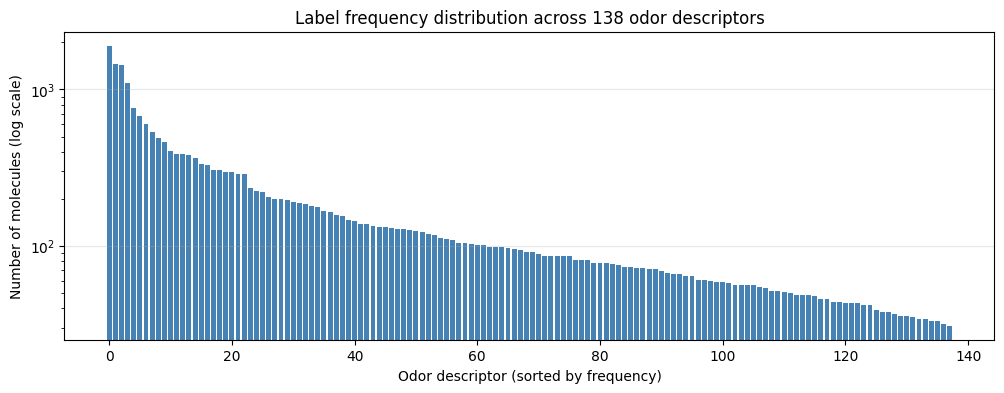

In [5]:
import matplotlib.pyplot as plt

counts = np.sort(labels.sum(axis=0))[::-1]

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(range(len(counts)), counts, color="steelblue")
ax.set_yscale("log")
ax.set_xlabel("Odor descriptor (sorted by frequency)")
ax.set_ylabel("Number of molecules (log scale)")
ax.set_title(f"Label frequency distribution across {NUM_CLASSES} odor descriptors")
ax.grid(axis="y", alpha=0.3)

if SAVE_OUTPUTS:
    plt.savefig(f"{FIGURES_DIR}/01_label_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

### 2.3. Chemical elements present

A quick inventory of the chemical space covered. Beyond the organic backbone (C, O, N, S) the
dataset includes halogens and a number of metals, which appear mostly in salts.

In [6]:
from rdkit import Chem
from tqdm import tqdm


def get_unique_atoms(smiles_list):
    """Scan every SMILES string and return the sorted set of chemical elements found."""
    unique_atoms = set()

    for smiles in tqdm(smiles_list, desc="Scanning molecules"):
        mol = Chem.MolFromSmiles(smiles)
        if mol is None:
            continue
        for atom in mol.GetAtoms():
            unique_atoms.add(atom.GetSymbol())

    sorted_atoms = sorted(unique_atoms)
    print(f"Found {len(sorted_atoms)} unique elements: {sorted_atoms}")
    return sorted_atoms


atoms_list = get_unique_atoms(df[SMILES_COLUMN].tolist())

Scanning molecules: 100%|██████████| 4983/4983 [00:00<00:00, 5123.12it/s]

Found 25 unique elements: ['Al', 'B', 'Bi', 'Br', 'C', 'Ca', 'Cl', 'Co', 'Cr', 'Cu', 'F', 'Fe', 'He', 'I', 'K', 'Mg', 'N', 'Na', 'O', 'P', 'S', 'Si', 'Ti', 'V', 'Zn']


### 2.4. An example molecule

Index 4 is 4-hydroxybenzaldehyde, labelled *phenolic*, *woody*, *nutty*, *vanilla*, *hay*,
*metallic* and *sweet* — a compact illustration of how a small structural change (the phenol
group) carries a rich olfactory profile.

SMILES      : O=Cc1ccc(O)cc1
Descriptors : phenolic;woody;nutty;vanilla;hay;metallic;sweet;almond;honey;balsamic


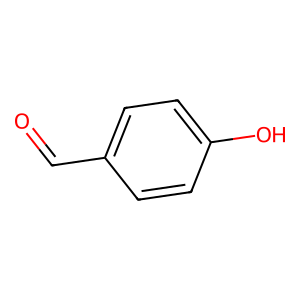

In [7]:
from rdkit.Chem import Draw

EXAMPLE_IDX = 4
example_smiles = df[SMILES_COLUMN][EXAMPLE_IDX]

print(f"SMILES      : {example_smiles}")
print(f"Descriptors : {df['descriptors'][EXAMPLE_IDX]}")

Draw.MolToImage(Chem.MolFromSmiles(example_smiles))

## 3. From SMILES to molecular graphs

`from_smiles` converts each SMILES string into a PyTorch Geometric `Data` object: **atoms become
nodes, bonds become edges**, with hydrogens left implicit.

Each node carries 9 features — atomic number, chirality, degree, formal charge, number of
hydrogens, radical electrons, hybridization, aromaticity and ring membership. Edge features
(bond type, stereochemistry, conjugation) are produced as well, but the GATv2 model below
operates on connectivity alone.

In [8]:
from torch_geometric.utils import from_smiles, to_networkx

df_graph = []
G = []

for i in range(len(df)):
    data = from_smiles(df[SMILES_COLUMN][i], with_hydrogen=0)
    data.x = data.x.float()
    data.y = torch.tensor(df.iloc[i, N_META_COLUMNS:].values.astype(float), dtype=torch.float)
    df_graph.append(data)
    G.append(to_networkx(data, to_undirected=True))

print(f"Converted {len(df_graph)} molecules to graphs.")
print(f"Node feature dimension: {df_graph[0].x.shape[1]}")

c:\Users\felip\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Converted 4983 molecules to graphs.
Node feature dimension: 9


### 3.1. Sanity checks on the graph representation

In [9]:
example_graph = df_graph[EXAMPLE_IDX]

print(f"Nodes (atoms)     : {example_graph.num_nodes}")
print(f"Edges (bonds x2)  : {example_graph.num_edges}")
print(f"Target vector     : {example_graph.y.shape[0]} labels, "
      f"{int(example_graph.y.sum())} positive")
print(f"\nNode feature matrix (first 5 atoms):\n{example_graph.x[:5]}")

Nodes (atoms)     : 9
Edges (bonds x2)  : 18
Target vector     : 138 labels, 10 positive

Node feature matrix (first 5 atoms):
tensor([[8., 0., 1., 5., 0., 0., 3., 0., 0.],
        [6., 0., 3., 5., 1., 0., 3., 0., 0.],
        [6., 0., 3., 5., 0., 0., 3., 1., 1.],
        [6., 0., 3., 5., 1., 0., 3., 1., 1.],
        [6., 0., 3., 5., 1., 0., 3., 1., 1.]])


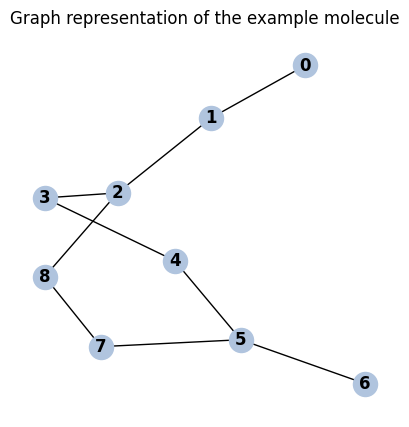

In [10]:
import networkx as nx

fig, ax = plt.subplots(figsize=(5, 5))
nx.draw(G[EXAMPLE_IDX], with_labels=True, font_weight="bold", node_color="lightsteelblue", ax=ax)
ax.set_title("Graph representation of the example molecule")
plt.show()

## 4. Data splitting

Two strategies are provided.

**Active:** a simple sequential 80/10/10 split. This reproduces the *naive* GATv2 row of the
results table.

**Commented out:** second-order iterative stratification, which preserves label *pair*
co-occurrence ratios across the three splits and is what the final reported results use.
Uncomment the cell in section 4.2 to switch.

### 4.1. Sequential split (active)

In [11]:
from torch_geometric.loader import DataLoader

total_size = len(df_graph)
train_size = int(total_size * TRAIN_RATIO)
val_size = int(total_size * VAL_RATIO)

train_data = df_graph[:train_size]
val_data = df_graph[train_size:train_size + val_size]
test_data = df_graph[train_size + val_size:]

train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)

print(f"Train / Val / Test: {len(train_data)} / {len(val_data)} / {len(test_data)}")

Train / Val / Test: 3986 / 498 / 499


### 4.2. Second-order iterative stratification (optional)

Standard random splitting destroys label co-occurrence ratios in multi-label data: isolating a
molecule to satisfy one label's distribution disrupts every label it co-occurs with. The
algorithm below preserves label-pair ratios across splits, distributing the rarest combinations
first, so that ultra-rare scent profiles are not excluded from evaluation.

To use it, uncomment this cell and run it **after** section 4.1 — it overwrites `train_data`,
`val_data`, `test_data` and the three loaders.

In [12]:
# !pip install scikit-multilearn
# from skmultilearn.model_selection import IterativeStratification
#
#
# def create_stratified_splits(df, label_columns, train_ratio=0.8, val_ratio=0.1, test_ratio=0.1):
#     X = np.arange(len(df)).reshape(-1, 1)
#     y = label_columns
#
#     holdout_ratio = val_ratio + test_ratio
#
#     stratifier_1 = IterativeStratification(
#         n_splits=2,
#         order=2,
#         sample_distribution_per_fold=[holdout_ratio, train_ratio]
#     )
#     train_idx, holdout_idx = next(stratifier_1.split(X, y))
#     print(f"   -> Step 1 Complete: {len(train_idx)} Train samples, {len(holdout_idx)} Holdout samples.")
#
#     relative_test_ratio = test_ratio / holdout_ratio
#     relative_val_ratio = 1.0 - relative_test_ratio
#
#     stratifier_2 = IterativeStratification(
#         n_splits=2,
#         order=2,
#         sample_distribution_per_fold=[relative_test_ratio, relative_val_ratio]
#     )
#     X_holdout = X[holdout_idx]
#     y_holdout = y[holdout_idx]
#
#     val_idx_relative, test_idx_relative = next(stratifier_2.split(X_holdout, y_holdout))
#     val_idx = holdout_idx[val_idx_relative]
#     test_idx = holdout_idx[test_idx_relative]
#     print(f"   -> Step 2 Complete: {len(val_idx)} Val samples, {len(test_idx)} Test samples.")
#
#     return df.iloc[train_idx].copy(), df.iloc[val_idx].copy(), df.iloc[test_idx].copy()
#
#
# def dataframe_to_graphs(subset):
#     graphs = []
#     for i in range(len(subset)):
#         data = from_smiles(subset[SMILES_COLUMN].iloc[i], with_hydrogen=0)
#         data.x = data.x.float()
#         data.y = torch.tensor(subset.iloc[i, N_META_COLUMNS:].values.astype(float), dtype=torch.float)
#         graphs.append(data)
#     return graphs
#
#
# df_train, df_val, df_test = create_stratified_splits(
#     df=df,
#     label_columns=df.iloc[:, N_META_COLUMNS:].values,
#     train_ratio=TRAIN_RATIO,
#     val_ratio=VAL_RATIO,
#     test_ratio=TEST_RATIO,
# )
#
# train_data = dataframe_to_graphs(df_train)
# val_data = dataframe_to_graphs(df_val)
# test_data = dataframe_to_graphs(df_test)
#
# train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
# val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False)
# test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)
#
# print(f"Train / Val / Test: {len(train_data)} / {len(val_data)} / {len(test_data)}")

## 5. Model: GATv2

In [13]:
import torch.nn.functional as F
from torch_geometric.nn import GATv2Conv, global_mean_pool


class SmellPredictorGATv2(torch.nn.Module):
    """Graph Attention Network v2 for multi-label odor prediction.

    GATv2 improves on the original GAT attention mechanism by applying the linear
    transformation after concatenating source and target node features, which allows
    expressive, fully dynamic attention scores between neighbouring atoms.

    Architecture
    ------------
    GATv2Conv (multi-head, concatenated) -> ELU -> dropout
    GATv2Conv (single head)              -> ELU
    global mean pooling                  -> linear head (138 labels)
    """

    def __init__(
        self,
        num_node_features,
        hidden_dim=HIDDEN_DIM,
        num_heads=NUM_HEADS,
        num_classes=NUM_CLASSES,
        dropout=DROPOUT,
    ):
        super().__init__()

        # First layer: several attention heads learn different attention patterns,
        # and their outputs are concatenated.
        self.gat1 = GATv2Conv(
            in_channels=num_node_features,
            out_channels=hidden_dim,
            heads=num_heads,
            dropout=dropout,
        )

        # Second layer: concat=False keeps the output dimension equal to hidden_dim.
        self.gat2 = GATv2Conv(
            in_channels=hidden_dim * num_heads,
            out_channels=hidden_dim,
            heads=1,
            concat=False,
            dropout=dropout,
        )

        self.fc = torch.nn.Linear(hidden_dim, num_classes)
        self.dropout = dropout

    def forward(self, data):
        """Return raw logits of shape (num_graphs, num_classes)."""
        x, edge_index, batch = data.x, data.edge_index, data.batch

        x = self.gat1(x, edge_index)
        x = F.elu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)

        x = self.gat2(x, edge_index)
        x = F.elu(x)

        x = global_mean_pool(x, batch)

        return self.fc(x)

## 6. Evaluation utilities

Under extreme zero-inflation, accuracy is misleading. Evaluation therefore relies on **AUROC**
(threshold-independent ranking quality), **AUPRC** (sensitive to class imbalance), and
**precision / recall / micro-F1** at a given decision threshold.

`threshold` accepts either a scalar or a tensor of 138 per-label thresholds, so the same
function serves both the naive and the optimized evaluation.

In [14]:
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)


def calculate_all_metrics(loader, model, device, criterion, threshold=0.5):
    """Evaluate the model on a loader.

    Parameters
    ----------
    threshold : float or torch.Tensor
        A single cutoff applied to every label, or a tensor of shape (num_classes,)
        holding one cutoff per label.

    Returns
    -------
    tuple of (avg_loss, auroc, aucpr, precision, recall, f1), all micro-averaged.
    """
    model.eval()
    total_loss = 0
    y_true_all, y_probs_all, y_pred_all = [], [], []

    with torch.no_grad():
        for batch in loader:
            batch = batch.to(device)
            out = model(batch)

            target = batch.y.view(batch.num_graphs, -1).float()
            total_loss += criterion(out, target).item()

            probs = torch.sigmoid(out)
            preds = (probs > threshold).float()

            y_true_all.append(target.cpu().numpy())
            y_probs_all.append(probs.cpu().numpy())
            y_pred_all.append(preds.cpu().numpy())

    y_true = np.vstack(y_true_all)
    y_probs = np.vstack(y_probs_all)
    y_pred = np.vstack(y_pred_all)

    return (
        total_loss / len(loader),
        roc_auc_score(y_true, y_probs, average="micro"),
        average_precision_score(y_true, y_probs, average="micro"),
        precision_score(y_true, y_pred, average="micro", zero_division=0),
        recall_score(y_true, y_pred, average="micro", zero_division=0),
        f1_score(y_true, y_pred, average="micro", zero_division=0),
    )


def collect_predictions(loader, model, device):
    """Return (y_true, y_probs) as stacked numpy arrays, for curve plotting."""
    model.eval()
    y_true_all, y_probs_all = [], []

    with torch.no_grad():
        for batch in loader:
            batch = batch.to(device)
            probs = torch.sigmoid(model(batch))
            y_true_all.append(batch.y.view(batch.num_graphs, -1).cpu().numpy())
            y_probs_all.append(probs.cpu().numpy())

    return np.vstack(y_true_all), np.vstack(y_probs_all)

## 7. Training

**Loss.** `BCEWithLogitsLoss` with a per-class `pos_weight` derived from label frequency in the
training split, so that missing a rare descriptor is penalised in proportion to its scarcity.

**Schedule.** Adam with Cosine Annealing and Warm Restarts, which periodically raises the
learning rate to help the model escape local minima — visible as the characteristic sawtooth
pattern in the training loss.

In [15]:
from torch.optim.lr_scheduler import CosineAnnealingWarmRestarts

model = SmellPredictorGATv2(num_node_features=df_graph[0].x.shape[1]).to(DEVICE)

# Per-class positive weights from the training split
stacked_y = torch.stack([data.y for data in train_data])
num_positives = torch.sum(stacked_y, dim=0)
num_negatives = len(train_data) - num_positives
pos_weight = (num_negatives / (num_positives + 1e-5)).to(DEVICE)

criterion = torch.nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = CosineAnnealingWarmRestarts(optimizer, T_0=SCHEDULER_T0, T_mult=1)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {n_params:,}")

Trainable parameters: 47,626


In [16]:
history = {k: [] for k in
           ["train_loss", "val_loss", "val_auroc", "val_aucpr",
            "val_precision", "val_recall", "val_f1"]}

print(f"Starting training ({EPOCHS} epochs) on {DEVICE}...")

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0

    for batch in train_loader:
        batch = batch.to(DEVICE)
        optimizer.zero_grad()
        out = model(batch)
        loss = criterion(out, batch.y.view(batch.num_graphs, -1).float())
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    scheduler.step()

    val_loss, val_auroc, val_aucpr, val_prec, val_rec, val_f1 = calculate_all_metrics(
        val_loader, model, DEVICE, criterion
    )

    history["train_loss"].append(train_loss / len(train_loader))
    history["val_loss"].append(val_loss)
    history["val_auroc"].append(val_auroc)
    history["val_aucpr"].append(val_aucpr)
    history["val_precision"].append(val_prec)
    history["val_recall"].append(val_rec)
    history["val_f1"].append(val_f1)

    if (epoch + 1) % 25 == 0:
        print(f"Epoch {epoch + 1:03d} | Val loss: {val_loss:.4f} | "
              f"F1: {val_f1:.4f} | AUROC: {val_auroc:.4f}")

print("Training complete.")

Starting training (500 epochs) on cpu...
Epoch 025 | Val loss: 0.8812 | F1: 0.1025 | AUROC: 0.7955
Epoch 050 | Val loss: 0.8646 | F1: 0.1068 | AUROC: 0.8025


RuntimeError: [enforce fail at alloc_cpu.cpp:117] data. DefaultCPUAllocator: not enough memory: you tried to allocate 1212416 bytes.

### 7.1. Training dynamics

Three things to read in these curves:

- **Loss.** Training loss decreases steadily while validation loss falls only briefly and then
  rises — the overfitting signature of attention models on this dataset.
- **Ranking metrics.** AUROC and AUPRC climb quickly and then plateau, *despite* the diverging
  loss. Probability calibration drifts, but the ability to rank positives above negatives holds.
- **Utility metrics at threshold 0.5.** Recall is very high and precision very low: the model
  fires on almost everything. This is exactly the failure the next section corrects.

In [ ]:
def plot_full_history(history, save_path=None):
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 5))

    ax1.plot(history["train_loss"], label="Train loss", color="blue", alpha=0.6)
    ax1.plot(history["val_loss"], label="Val loss", color="red", linestyle="--")
    ax1.set_title("Loss over time (lower is better)")
    ax1.set_xlabel("Epochs")

    ax2.plot(history["val_auroc"], label="AUROC", color="green")
    ax2.plot(history["val_aucpr"], label="AUPRC", color="purple")
    ax2.set_title("Ranking metrics (higher is better)")
    ax2.set_xlabel("Epochs")
    ax2.set_ylim([0, 1])

    ax3.plot(history["val_precision"], label="Precision", color="cyan", linestyle=":")
    ax3.plot(history["val_recall"], label="Recall", color="orange", linestyle=":")
    ax3.plot(history["val_f1"], label="F1 score", color="black")
    ax3.set_title("Utility metrics (threshold = 0.5)")
    ax3.set_xlabel("Epochs")
    ax3.set_ylim([0, 1])

    for ax in (ax1, ax2, ax3):
        ax.grid(True, alpha=0.3)
        ax.legend()

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()


plot_full_history(
    history,
    save_path=f"{FIGURES_DIR}/06_gatv2_training.png" if SAVE_OUTPUTS else None,
)

## 8. Test evaluation

### 8.1. Naive evaluation (threshold = 0.5)

The baseline every architecture is compared against before post-processing.

In [ ]:
_, auroc_naive, aucpr_naive, prec_naive, rec_naive, f1_naive = calculate_all_metrics(
    test_loader, model, DEVICE, criterion, threshold=0.5
)

print("GATv2 - naive evaluation (threshold = 0.5)")
print(f"{'AUROC':<10} | {'AUPRC':<10} | {'Precision':<10} | {'Recall':<10} | {'F1 Score':<10}")
print("-" * 62)
print(f"{auroc_naive:<10.4f} | {aucpr_naive:<10.4f} | {prec_naive:<10.4f} | "
      f"{rec_naive:<10.4f} | {f1_naive:<10.4f}")
print("-" * 62)

### 8.2. Per-label threshold optimization

A single global cutoff of 0.5 is arbitrary for 138 labels of wildly different frequency. The
sweep below finds, **independently for each label**, the cutoff that maximises F1 on the
*validation* set. Those thresholds are then frozen and applied to the test set — the validation
set is used for tuning, the test set only for reporting.

This is the highest-impact post-processing step in the whole pipeline.

In [ ]:
def find_per_label_thresholds(val_loader, model, device, num_classes=NUM_CLASSES):
    """Sweep decision thresholds independently for each label on the validation set.

    Returns an array of shape (num_classes,) with the F1-maximising cutoff per label.
    Labels absent from the validation set keep the default of 0.5.
    """
    y_true, y_probs = collect_predictions(val_loader, model, device)
    best_thresholds = np.full(num_classes, 0.5)

    print(f"Sweeping thresholds for all {num_classes} labels individually...")

    for class_idx in range(num_classes):
        y_true_class = y_true[:, class_idx]
        y_probs_class = y_probs[:, class_idx]

        # Skip labels that never occur in the validation set
        if np.sum(y_true_class) == 0:
            continue

        best_f1 = 0.0
        for thresh in np.arange(0.01, 1.0, 0.01):
            current_f1 = f1_score(
                y_true_class, (y_probs_class >= thresh).astype(int), zero_division=0
            )
            if current_f1 > best_f1:
                best_f1 = current_f1
                best_thresholds[class_idx] = thresh

    print(f"Done. Found {num_classes} optimal thresholds.")
    return best_thresholds


optimal_thresholds = find_per_label_thresholds(val_loader, model, DEVICE)
thresholds_tensor = torch.tensor(optimal_thresholds, dtype=torch.float32).to(DEVICE)

In [ ]:
_, auroc_opt, aucpr_opt, prec_opt, rec_opt, f1_opt = calculate_all_metrics(
    test_loader, model, DEVICE, criterion, threshold=thresholds_tensor
)

print("GATv2 - per-label optimized thresholds")
print(f"{'AUROC':<10} | {'AUPRC':<10} | {'Precision':<10} | {'Recall':<10} | {'F1 Score':<10}")
print("-" * 62)
print(f"{auroc_opt:<10.4f} | {aucpr_opt:<10.4f} | {prec_opt:<10.4f} | "
      f"{rec_opt:<10.4f} | {f1_opt:<10.4f}")
print("-" * 62)
print(f"\nF1 improvement: {f1_naive:.4f} -> {f1_opt:.4f} "
      f"({(f1_opt / f1_naive - 1) * 100:+.1f}%)")

In [ ]:
results = pd.DataFrame(
    [
        ["GATv2", "Naive (threshold = 0.5)", auroc_naive, aucpr_naive,
         prec_naive, rec_naive, f1_naive],
        ["GATv2", "Per-label thresholds", auroc_opt, aucpr_opt,
         prec_opt, rec_opt, f1_opt],
    ],
    columns=["model", "setting", "auroc", "aucpr", "precision", "recall", "f1_score"],
)

if SAVE_OUTPUTS:
    results.to_csv(f"{TABLES_DIR}/gatv2_results.csv", index=False)

results

### 8.3. What the thresholds reveal

The optimal cutoffs are interpretable in their own right. A **high** threshold means the model
separates that descriptor confidently and can afford to be strict; a **low** threshold means it
struggles and the bar has to be lowered to catch any true positives at all.

In [ ]:
def analyze_thresholds(thresholds, smell_names, top_n=5):
    """Print the descriptors with the highest and lowest optimal thresholds."""
    sorted_indices = np.argsort(thresholds)

    print("=" * 46)
    print("MODEL CONFIDENCE ANALYSIS")
    print("=" * 46)

    print(f"\nMost confident descriptors (highest thresholds):")
    for rank, idx in enumerate(sorted_indices[-top_n:][::-1], 1):
        print(f"   {rank}. {smell_names[idx].capitalize():<15} | Threshold: {thresholds[idx]:.2f}")

    print(f"\nLeast confident descriptors (lowest thresholds):")
    for rank, idx in enumerate(sorted_indices[:top_n], 1):
        print(f"   {rank}. {smell_names[idx].capitalize():<15} | Threshold: {thresholds[idx]:.2f}")


analyze_thresholds(optimal_thresholds, label_names)

if SAVE_OUTPUTS:
    pd.DataFrame({"label": label_names, "optimal_threshold": optimal_thresholds}).to_csv(
        f"{TABLES_DIR}/gatv2_per_label_thresholds.csv", index=False
    )

## 9. Ranking analysis

### 9.1. ROC and Precision-Recall curves

Micro-averaged over all 138 labels. The PR curve is the more informative of the two here: with
97% negatives, a ROC curve flatters any model, while precision-recall exposes how quickly
precision collapses as recall increases.

In [ ]:
from sklearn.metrics import auc, precision_recall_curve, roc_curve

y_true_test, y_probs_test = collect_predictions(test_loader, model, DEVICE)

fpr, tpr, _ = roc_curve(y_true_test.ravel(), y_probs_test.ravel())
roc_auc = auc(fpr, tpr)

precision_curve, recall_curve, _ = precision_recall_curve(
    y_true_test.ravel(), y_probs_test.ravel()
)
auprc = auc(recall_curve, precision_curve)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(fpr, tpr, color="darkorange", lw=2, label=f"Micro-average ROC (AUC = {roc_auc:.3f})")
ax1.plot([0, 1], [0, 1], color="navy", lw=1.5, linestyle="--", label="Random")
ax1.set_xlabel("False positive rate")
ax1.set_ylabel("True positive rate")
ax1.set_title("Multi-label ROC curve (micro-average)")
ax1.legend(loc="lower right")

ax2.step(recall_curve, precision_curve, color="blue", lw=2, where="post",
         label=f"Micro-average PR (AUPRC = {auprc:.3f})")
ax2.set_xlabel("Recall")
ax2.set_ylabel("Precision")
ax2.set_title("Multi-label Precision-Recall curve (micro-average)")
ax2.legend(loc="upper right")

for ax in (ax1, ax2):
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.grid(alpha=0.3)

plt.tight_layout()
if SAVE_OUTPUTS:
    plt.savefig(f"{FIGURES_DIR}/07_gatv2_roc_pr_curves.png", dpi=300, bbox_inches="tight")
plt.show()

### 9.2. Per-class AUC

The micro-average hides a wide spread. Computing AUC label by label shows that frequent
descriptors are learned well while the rarest ones are barely better than chance — the single
most important caveat on the headline metrics.

In [ ]:
class_aucs = []

for i in range(y_true_test.shape[1]):
    # Only computable for labels that actually occur in the test set
    if np.sum(y_true_test[:, i]) > 0:
        class_fpr, class_tpr, _ = roc_curve(y_true_test[:, i], y_probs_test[:, i])
        class_aucs.append(auc(class_fpr, class_tpr))
    else:
        class_aucs.append(np.nan)

class_aucs = np.array(class_aucs)
evaluable = np.sum(~np.isnan(class_aucs))

print(f"Labels present in the test set : {evaluable} / {NUM_CLASSES}")
print(f"Mean AUC across labels         : {np.nanmean(class_aucs):.4f}")
print(f"Best  : {label_names[np.nanargmax(class_aucs)]} ({np.nanmax(class_aucs):.4f})")
print(f"Worst : {label_names[np.nanargmin(class_aucs)]} ({np.nanmin(class_aucs):.4f})")
print(f"Labels below 0.5 (worse than chance): {np.nansum(class_aucs < 0.5):.0f}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(class_aucs[~np.isnan(class_aucs)], bins=20, color="skyblue", edgecolor="black")
ax.axvline(np.nanmean(class_aucs), color="red", linestyle="--",
           label=f"Mean = {np.nanmean(class_aucs):.3f}")
ax.axvline(0.5, color="gray", linestyle=":", label="Random (0.5)")
ax.set_xlabel("AUC")
ax.set_ylabel("Number of odor descriptors")
ax.set_title("Distribution of per-class AUC")
ax.legend()
ax.grid(axis="y", alpha=0.3)

if SAVE_OUTPUTS:
    plt.savefig(f"{FIGURES_DIR}/08_gatv2_per_class_auc.png", dpi=300, bbox_inches="tight")
plt.show()

## 10. Summary

- The GATv2 learns a usable ranking of odor descriptors (micro-AUROC in the 0.83–0.86 range),
  comparable to the literature-approximated GCN, but it **overfits**: validation loss rises
  after the first epochs even though ranking quality keeps improving.
- At the default 0.5 cutoff the model is practically unusable — very high recall, very low
  precision. **Per-label threshold optimization roughly doubles the F1-score** without touching
  a single weight, which is the central methodological finding of this project.
- Per-class AUC reveals that performance is concentrated in the frequent descriptors; the rarest
  labels remain close to chance.

Next steps are discussed in the *Limitations and Future Work* section of the repository README:
stronger regularization for the attention layers, exploiting the edge features the featurizer
already produces, and a classical fingerprint baseline for comparison.